# HW05 (d) - First-stage two-tone gain and IIP3

Use 5.79/5.81-GHz tones and a 50-ohm Thevenin source. Report source-referenced gain separately from internal-node gain. The original submission measurement and an independent coherent-window check are shown side by side.

**Kernel: ECE6420 (Local).** Local **Run All** runs computation through SSH and renders plots here. Set `EXECUTION_MODE = "review"` in the setup cell to redraw saved data without SSH.

[Assignment](../references/HW5_LNA_sim_revised.pdf) | [Solution](../references/ECE6420_HW5_solution_Fall_2026.pdf)

The original IIP3 method is preserved. Its floating-point time-window boundary can omit a sample; the results include a separate coherent-window check. A single-point intercept still requires cubic-scaling validation.

In [1]:
from pathlib import Path
import sys
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for base in candidates for p in (base, base / "HW05")
             if (p / "netlists" / "reference" / "input.scs").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the Gatech-ECE6420 checkout.")
sys.path.insert(0, str(ROOT / "lib"))
from runtime import *
from remote_bridge import run_remote_parts
EXECUTION_MODE = execution_mode()  # Default: remote. Set "review" here to redraw saved data only.
RUN_SIMULATIONS = EXECUTION_MODE == "server"
if RUN_SIMULATIONS:
    preflight()
else:
    from plots import show_part, show_summary, spectrum
print("Kernel interpreter:", sys.executable)
print("Mode:", EXECUTION_MODE, "| project:", ROOT)


Kernel interpreter: /Library/Frameworks/Python.framework/Versions/3.12/bin/python3
Mode: review | project: /Users/jeonsang-eon/Gatech-ECE6420/HW05


## Parameters
These values are editable in this local kernel. The remote Run cell sends their current values to the server.

In [2]:
import re
import math
import cmath
import tune_c
WORK = GENERATED / "d_twotone.scs"
RESULTS = SIMULATION / "d"
F1, F2 = 5.79e9, 5.81e9
IM31, IM32 = 2*F1-F2, 2*F2-F1
RS = 50.0
ATONE = 20e-3
TSTOP, WINDOW_START = 160e-9, 60e-9
MAXSTEP, STROBE = 3e-12, 5e-12


## Measurement helpers
Build analysis netlists from the trusted reference and parse actual Spectre ASCII traces.

In [3]:
def run():
    return run_spectre(WORK, RESULTS)

def build_netlist(w_um, l_nh):
    tune_c.make_netlist(w_um, l_nh, "rin")
    text = tune_c.WORK.read_text()

    text = re.sub(r"^I18 .*?\n", "", text, flags=re.M)
    text = re.sub(r"^I15 .*?\n", "", text, flags=re.M)
    prefix = text.split("simulatorOptions options", 1)[0]

    stimulus = f'''
VT1 (tone1 0) vsource type=sine dc=0 ampl={ATONE:.12g} freq={F1:.12g}
VT2 (VinSrc tone1) vsource type=sine dc=0 ampl={ATONE:.12g} freq={F2:.12g}
RSRC (VinSrc VinPre) resistor r={RS:.12g}
CIN_D (VinPre VinNode) capacitor c=100p

simulatorOptions options temp=27 tnom=27 gmin=1e-12 reltol=1e-4
tran tran stop={TSTOP:.12g} maxstep={MAXSTEP:.12g} strobeperiod={STROBE:.12g}
save Vout VinNode VinSrc
saveOptions options save=allpub
'''
    write_netlist(WORK, prefix + stimulus)

def read_tran():
    from psf import read_ascii
    names = ['Vout', 'VinNode', 'VinSrc']
    t, traces = read_ascii(find_result(RESULTS, "tran"), "time", names)
    if len(t) < 100:
        raise ValueError("Not enough transient samples")
    return (t.tolist(), *(traces[name].tolist() for name in names))


def tone_amp(t, y, f):
    pts = [(ti, yi) for ti, yi in zip(t, y) if WINDOW_START <= ti < TSTOP]
    if len(pts) < 100:
        raise RuntimeError("not enough transient samples")
    mean = sum(yi for _, yi in pts) / len(pts)
    w = 2 * math.pi * f
    z = sum((yi - mean) * cmath.exp(-1j * w * ti) for ti, yi in pts)
    return 2 * abs(z) / len(pts)

def gmean(a, b):
    return math.sqrt(max(a, 1e-300) * max(b, 1e-300))


## Run and plot
Run this local cell to synchronize source, compute remotely, fetch numerical data, and render the plots immediately below. Current parameter-cell values are sent to the worker.

In [4]:
if EXECUTION_MODE == "remote":
    run_remote_parts("d", {"d": {name: globals()[name] for name in ['F1', 'F2', 'RS', 'ATONE', 'TSTOP', 'WINDOW_START', 'MAXSTEP', 'STROBE']}})

    show_part("d")

## Server analysis
These cells execute in the server worker. A local Run delegates computation through the preceding SSH bridge; review mode uses saved numerical data.

In [5]:
if RUN_SIMULATIONS:
    meta = load_meta()
    c = require_part(meta, "c")
    cout = c["outputs"]
    w_um = float(cout["W1_um"])
    l_nh = float(cout["L1_nH"])

    print("HW5(d): two-tone shortcut IIP3 + voltage gain")
    print(f"Loaded part (c): W1={w_um:.6f} um, L1={l_nh:.6f} nH")

    build_netlist(w_um, l_nh)
    run()
    t, vo, vi, vs = read_tran()

    of1, of2 = tone_amp(t, vo, F1), tone_amp(t, vo, F2)
    oi1, oi2 = tone_amp(t, vo, IM31), tone_amp(t, vo, IM32)
    nf1, nf2 = tone_amp(t, vi, F1), tone_amp(t, vi, F2)
    sf1, sf2 = tone_amp(t, vs, F1), tone_amp(t, vs, F2)

    af = gmean(of1, of2)
    aim = gmean(oi1, oi2)
    anode = gmean(nf1, nf2)
    asrc = gmean(sf1, sf2)

    delta_db = 20 * math.log10(af / aim)
    gain_source_db = 20 * math.log10(af / asrc)
    gain_node_db = 20 * math.log10(af / anode)

    ain_dbv = 20 * math.log10(asrc)
    iip3_dbv = ain_dbv + delta_db / 2
    iip3_vpk = 10 ** (iip3_dbv / 20)

    pin_w = asrc * asrc / (8 * RS)
    pin_dbm = 10 * math.log10(pin_w / 1e-3)
    iip3_dbm = pin_dbm + delta_db / 2

    meta["parts"]["d"] = {
        "status": "complete",
        "completed_utc": now(),
        "depends_on": ["c"],
        "upstream": {
            "c_W1_um": w_um,
            "c_L1_nH": l_nh,
            "c_Rin_ohm": cout["Rin_ohm"],
        },
        "inputs": {
            "f1_Hz": F1,
            "f2_Hz": F2,
            "source_resistance_ohm": RS,
            "open_circuit_tone_Vpk_each": ATONE,
            "shortcut_rule": "IIP3_log = input_log + (fundamental_minus_IM3)_dB/2",
        },
        "outputs": {
            "Vout_fund_Vpk_geomean": af,
            "Vout_IM3_Vpk_geomean": aim,
            "fund_minus_IM3_dB": delta_db,
            "voltage_gain_from_Fig1_vin_source_dB": gain_source_db,
            "voltage_gain_from_VinNode_dB": gain_node_db,
            "IIP3_dBV_peak": iip3_dbv,
            "IIP3_Vpk": iip3_vpk,
            "IIP3_dBm_available_50ohm": iip3_dbm,
        },
    }
    save_meta(meta)

    print("\n===== HW5(d) RESULT =====")
    print(f"tones              = {F1/1e9:.3f}, {F2/1e9:.3f} GHz")
    print(f"Vout fundamental   = {af:.6g} Vpk")
    print(f"Vout IM3           = {aim:.6g} Vpk")
    print(f"Delta              = {delta_db:.3f} dB")
    print(f"Voltage gain       = {gain_source_db:.3f} dB (Vout/Fig.1 vin source)")
    print(f"Gain from VinNode  = {gain_node_db:.3f} dB")
    print(f"IIP3               = {iip3_dbv:.3f} dBV")
    print(f"IIP3               = {iip3_vpk:.6g} Vpk")
    print(f"IIP3               = {iip3_dbm:.3f} dBm (50-ohm available-power convention)")
    print(f"metadata -> {META}")
    print("Sanity check: change ATONE and confirm IIP3 stays similar.")
else:
    print("Using numerical data from the remote bridge or review cache.")


Using numerical data from the remote bridge or review cache.


## Retain actual curves
The server exports compressed numerical traces from real PSF results. Plots are rendered by the local kernel.

In [6]:
if RUN_SIMULATIONS:
    t, vo, vi, vs = read_tran()
    save_curve("d_tran", time_s=t, Vout=vo, VinNode=vi, VinSrc=vs)


## Local results and plots
Gain is in dB, spectra are in dBV peak, and voltage intercepts are in Vpk/dBV peak. Available input power uses Vopen-circuit,pk^2/(8*Rs). FFTs use stem plots.

| Metric | Measured value |
|---|---|
| IIP3_Vpk | 0.2988269 |
| IIP3_dBV_peak | -10.49161 |
| IIP3_dBm_available_50ohm | -6.512207 |
| Vout_IM3_Vpk_geomean | 0.000654151 |
| Vout_fund_Vpk_geomean | 0.1460205 |
| fund_minus_IM3_dB | 46.97472 |
| voltage_gain_from_Fig1_vin_source_dB | 17.26724 |
| voltage_gain_from_VinNode_dB | 19.60006 |

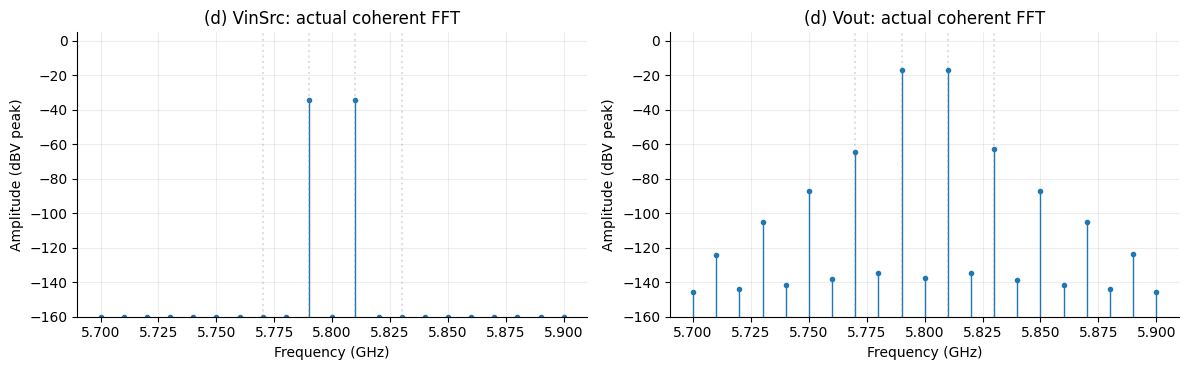

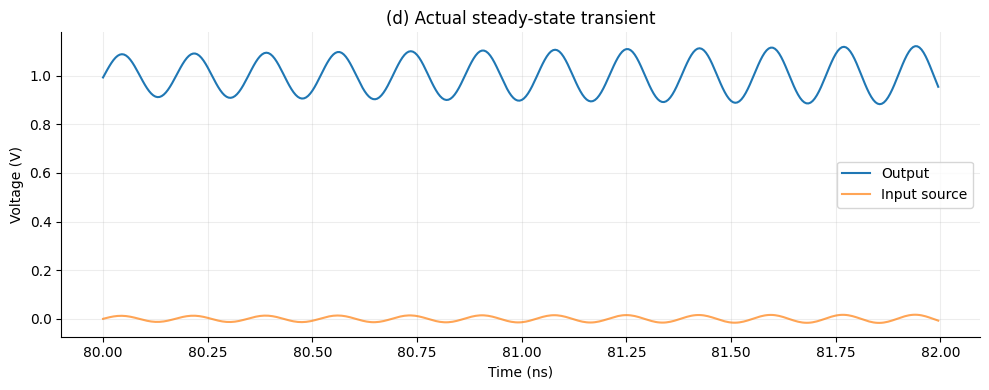

| IIP3 method | Samples | IIP3 (dBV peak) |
|---|---|---|
| Preserved submission projection | 19999 | -10.4916 |
| Exact coherent-window check | 20000 | -10.4927 |

The original window selected **19999** samples; the coherent check uses **20000** samples over exactly 100 ns. Coherent minus legacy IIP3: **-0.001 dB**. Original submission metrics remain above. The coherent single-point estimate also needs an amplitude sweep before treating it as a validated intercept.

In [7]:
if EXECUTION_MODE == "review":
    show_part("d")